# 07c. Time Series Forecasting and A/B Test Design

Two questions that follow from the early-warning model of notebook 07a.

**Part A, time series.** Platform activity is a time series. Can the load on the platform (and therefore on support staff) in weeks 5 to 8 be forecast from the first four weeks of a presentation? This is the same prediction day (28) as the student-level model, so a forecast is available when the alerts go out.

**Part B, A/B test design.** The model flags students; whether contacting them *helps* is a causal question that the observational data cannot answer. This part designs the trial that can, with sample sizes, power simulations, and a demonstration of why the obvious observational comparison fails.

Everything in Part A uses only activity counts (no student labels). Part B uses the 2014 predictions from notebook 07a as a realistic population of flagged students.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import acf
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportion_confint
import statsmodels.api as sm

warnings.filterwarnings("ignore", module="statsmodels")
RANDOM_STATE = 42
RAW, PROC, OUT = Path("../data/raw"), Path("../data/processed"), Path("../outputs")
FIG = OUT / "figures"
KEY = ["code_module", "code_presentation", "id_student"]; MPK = ["code_module", "code_presentation"]

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
def savefig(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

# Part A. Time series
## A1. Daily platform activity per module-presentation

In [2]:
courses = pd.read_csv(RAW / "courses.csv"); asm = pd.read_csv(RAW / "assessments.csv", na_values=["?"])
sv = pd.read_csv(RAW / "studentVle.csv", usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"],
                 dtype={"code_module": "category", "code_presentation": "category", "id_student": "int32", "date": "int16", "sum_click": "int16"})
clicks = sv.groupby(MPK + ["date"], observed=True).sum_click.sum()
active = sv.drop_duplicates(MPK + ["id_student", "date"]).groupby(MPK + ["date"], observed=True).size()
del sv
SER, ACT, LEN = {}, {}, {}
present = set(clicks.index.droplevel(2).unique())
for r in courses.itertuples():
    k = (r.code_module, r.code_presentation); LEN[k] = r.module_presentation_length
    idx = pd.RangeIndex(-25, r.module_presentation_length + 1)
    SER[k] = clicks.loc[k].reindex(idx, fill_value=0).astype(float) if k in present else pd.Series(0.0, index=idx)
    ACT[k] = active.loc[k].reindex(idx, fill_value=0).astype(float) if k in present else pd.Series(0.0, index=idx)
keys = sorted(SER)
print(f"{len(keys)} module-presentation series; days -25 to course end; shortest course {min(LEN.values())} days")
summ = pd.DataFrame({f"{m} {p}": dict(days=LEN[(m, p)], total_clicks=SER[(m, p)].sum(), peak_day_clicks=SER[(m, p)].max(), zero_days=int((SER[(m, p)].loc[0:LEN[(m, p)] - 1] == 0).sum())) for m, p in keys}).T
display(summ.describe().loc[["min", "50%", "max"]])

22 module-presentation series; days -25 to course end; shortest course 234 days


,days,total_clicks,peak_day_clicks,zero_days
min,234.000,"399,628.000","6,419.000",0.000
50%,261.500,"1,412,609.000","20,564.000",0.000
max,269.000,"5,281,809.000","73,321.000",2.000


**Observed.** The 22 series cover 234 to 269 days. A presentation generates between 0.4 and 5.3 million clicks (median 1.4 million), and on its busiest day between 6,400 and 73,000 (median 20,600). Only 0 to 2 days in a whole course have no activity at all.
**Why it matters.** Activity is far from stationary: it starts high, decays over the first weeks, spikes at deadlines and again before the final exam, then collapses. The first four weeks are therefore the start-up phase, not a representative sample of the course.

## A2. Structure: trend, weekly cycle and deadlines

STL decomposition (period 7, robust) of each series over the course. The strength of a component is 1 minus the variance of the remainder divided by the variance of the component plus remainder (0 = absent, 1 = dominant).

In [3]:
rows = []
for k in keys:
    y = SER[k].loc[0:LEN[k] - 1]
    res = STL(y.values, period=7, robust=True).fit()
    Fs = max(0, 1 - np.var(res.resid) / np.var(res.seasonal + res.resid)); Ft = max(0, 1 - np.var(res.resid) / np.var(res.trend + res.resid))
    detr = pd.Series(y.values - res.trend); rows.append(dict(series=f"{k[0]} {k[1]}", trend_strength=Ft, weekly_strength=Fs, acf_lag7=acf(detr.dropna(), nlags=7)[7], start_to_peak_day=int(np.argmax(y.values))))
strength = pd.DataFrame(rows).set_index("series")
strength.to_csv(OUT / "ts_structure_strength.csv"); display(strength.describe().loc[["min", "50%", "max"]])

,trend_strength,weekly_strength,acf_lag7,start_to_peak_day
min,0.325,0.076,-0.102,2.000
50%,0.679,0.230,0.128,21.500
max,0.837,0.435,0.307,240.000


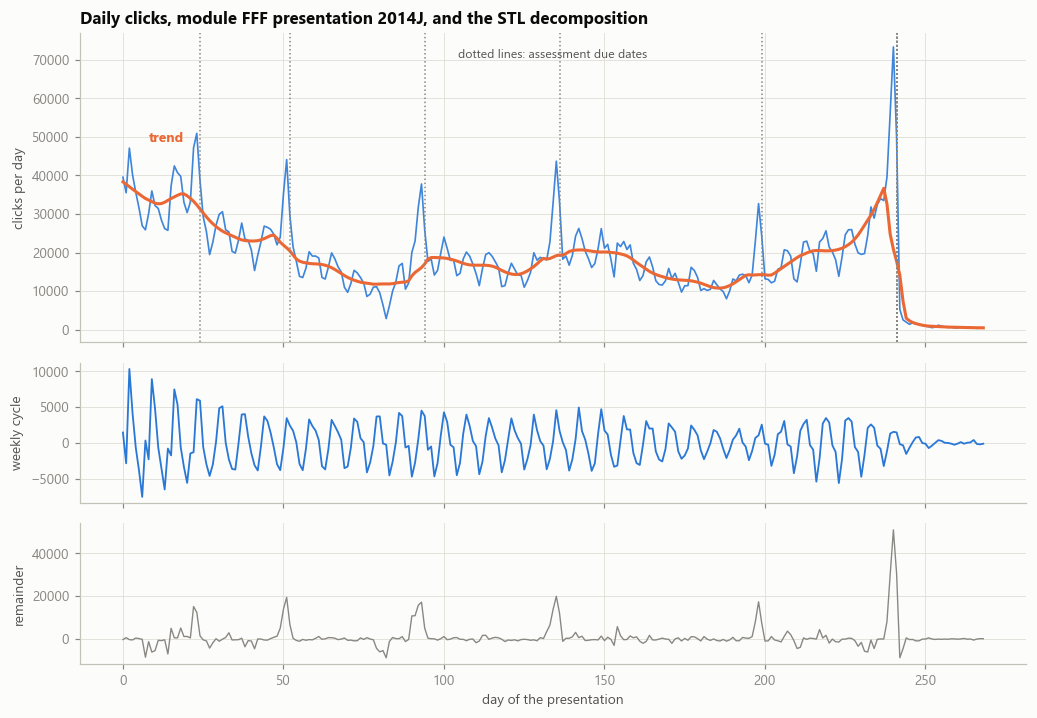

In [4]:
ex = ("FFF", "2014J"); y = SER[ex].loc[0:LEN[ex] - 1]; res = STL(y.values, period=7, robust=True).fit()
due = asm[(asm.code_module == ex[0]) & (asm.code_presentation == ex[1]) & asm.date.notna() & (asm.assessment_type != "Exam")]
fig, axes = plt.subplots(3, 1, figsize=(9.5, 6.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
ax = axes[0]; ax.plot(y.index, y.values, color=C1, linewidth=1.1, alpha=0.9); ax.plot(y.index, res.trend, color=C2, linewidth=2)
for d_, t_ in zip(due.date, due.assessment_type): ax.axvline(d_, color=MUTED, linestyle=":", linewidth=1)
ax.text(0.5, 0.95, "dotted lines: assessment due dates", transform=ax.transAxes, ha="center", va="top", color=INK2, fontsize=8)
ax.text(8, res.trend[8] * 1.45, "trend", color=C2, fontsize=9, fontweight="bold"); ax.set_ylabel("clicks per day"); ax.set_title(f"Daily clicks, module {ex[0]} presentation {ex[1]}, and the STL decomposition")
axes[1].plot(y.index, res.seasonal, color=C1, linewidth=1.2); axes[1].set_ylabel("weekly cycle")
axes[2].plot(y.index, res.resid, color=MUTED, linewidth=0.9); axes[2].set_ylabel("remainder"); axes[2].set_xlabel("day of the presentation")
fig.tight_layout(); savefig(fig, "07c_stl_example.png"); plt.show()

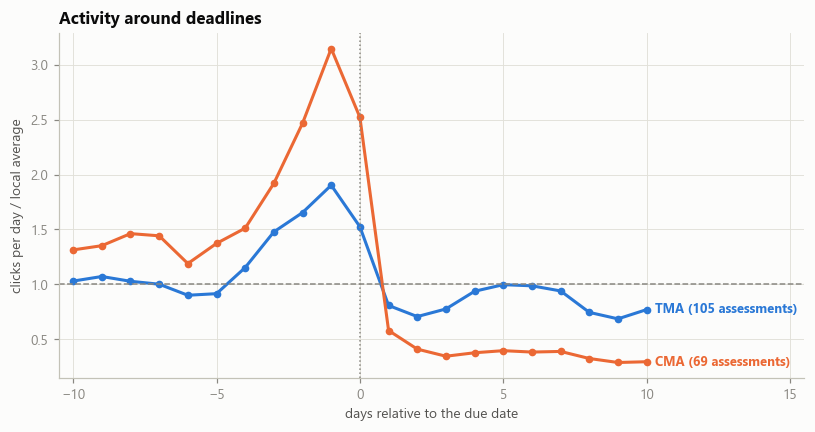

type     CMA   TMA
offset            
-7     1.440 1.000
-3     1.920 1.480
-2     2.470 1.650
-1     3.150 1.900
 0     2.520 1.520
 1     0.580 0.810
 3     0.350 0.780
 7     0.390 0.940
assessments used in the event study: {'CMA': 69, 'TMA': 105}


In [5]:
# Event study: activity around assessment due dates, relative to the local average level
rows = []
for k in keys:
    y = SER[k]; n = LEN[k]
    for a in asm[(asm.code_module == k[0]) & (asm.code_presentation == k[1]) & asm.date.notna() & (asm.assessment_type.isin(["TMA", "CMA"]))].itertuples():
        d = int(a.date)
        if d < 16 or d > n - 16: continue
        base = y.loc[d - 14:d + 14].mean()
        if base <= 0: continue
        for off in range(-10, 11): rows.append(dict(series=f"{k[0]} {k[1]}", aid=a.id_assessment, type=a.assessment_type, offset=off, ratio=y.loc[d + off] / base))
ev = pd.DataFrame(rows)
curve = ev.groupby(["type", "offset"]).ratio.mean().unstack(0)
n_assess = ev.groupby("type").aid.nunique().to_dict()
fig, ax = plt.subplots(figsize=(7.6, 4))
for typ, col in (("TMA", C1), ("CMA", C2)):
    ax.plot(curve.index, curve[typ], "-o", color=col, linewidth=2, markersize=4)
    ax.text(10.3, curve[typ].iloc[-1], f"{typ} ({n_assess[typ]} assessments)", color=col, fontsize=8.5, fontweight="bold", va="center")
ax.axhline(1, color=MUTED, linestyle="--", linewidth=1); ax.axvline(0, color=MUTED, linestyle=":", linewidth=1); ax.set_xlim(-10.5, 15.5)
ax.set_xlabel("days relative to the due date"); ax.set_ylabel("clicks per day / local average"); ax.set_title("Activity around deadlines")
fig.tight_layout(); savefig(fig, "07c_deadline_event_study.png"); plt.show()
print(curve.loc[[-7, -3, -2, -1, 0, 1, 3, 7]].round(2).to_string())
print("assessments used in the event study:", n_assess)

**Observed (decomposition).** In the 22 series the trend explains much of the variation (strength 0.33 to 0.84, median 0.68), while the weekly cycle is weak to moderate (strength 0.08 to 0.44, median 0.23; autocorrelation at lag 7 of the detrended series 0.13 on average). The largest feature is the deadline calendar: in the example (module FFF, 2014J) every due date is followed by a peak, and the final exam produces 73,000 clicks in a day.
**Deadlines are the dominant short-term pattern.** Across 105 tutor-marked and 69 computer-marked assessments, activity on the day before the due date is **1.9 times** (tutor-marked) and **3.2 times** (computer-marked) the local average, and it falls to 0.8 and 0.6 times on the day after (computer-marked work stays at 0.35 to 0.4 times for the next week).
**Why it matters.** A forecast that only repeats the last week will miss deadline peaks, which are known in advance from the course schedule. A calendar-aware model is the natural next step.

## A3. Forecasting days 28 to 55 from days 0 to 27

For each of the 22 series the first 28 days are the training window and the next 28 the holdout. Methods:

- **Seasonal naive:** repeat the last 7 days. **Flat mean:** the average of the last 7 days. **Naive:** the last value.
- **Holt-Winters:** additive level, damped trend and weekly seasonality, fitted to the 28 training points.
- **Analog profile (2014 presentations that have a 2013 twin, same module and same start month):** last year's profile for days 28 to 55, rescaled by the ratio of the two years' activity in days 14 to 27.

Error measure: MASE = mean absolute error in the holdout divided by the in-sample mean absolute error of the seasonal naive forecast (below 1 beats it); also sMAPE and total bias.

In [6]:
H, TRAIN = 28, 28
def fc_methods(tr):
    out = {"naive": np.repeat(tr[-1], H), "flat mean (last week)": np.repeat(tr[-7:].mean(), H), "seasonal naive": np.tile(tr[-7:], H // 7)}
    try:
        m = ExponentialSmoothing(tr, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7, initialization_method="estimated").fit(optimized=True)
        out["Holt-Winters (damped, weekly)"] = np.clip(m.forecast(H), 0, None)
    except Exception: out["Holt-Winters (damped, weekly)"] = out["seasonal naive"]
    return out
def metrics(tr, act, f):
    scale = np.mean(np.abs(tr[7:] - tr[:-7])); mae = np.mean(np.abs(act - f))
    return dict(mase=mae / scale, smape=np.mean(2 * np.abs(act - f) / (np.abs(act) + np.abs(f) + 1e-9)), bias=(f.sum() - act.sum()) / act.sum())
twin = {k: (k[0], f"2013{k[1][4]}") for k in keys if k[1].startswith("2014") and (k[0], f"2013{k[1][4]}") in SER}
rows = []
for k in keys:
    y = SER[k].loc[0:TRAIN + H - 1].values; tr, act = y[:TRAIN], y[TRAIN:]
    fcs = fc_methods(tr)
    if k in twin:
        yt = SER[twin[k]].loc[0:TRAIN + H - 1].values; ratio = tr[14:28].sum() / max(yt[14:28].sum(), 1.0); fcs["analog profile (last year's twin)"] = yt[TRAIN:] * ratio
    for name, f in fcs.items(): rows.append(dict(series=f"{k[0]} {k[1]}", has_twin=k in twin, method=name, **metrics(tr, act, f)))
fc = pd.DataFrame(rows); fc.to_csv(OUT / "ts_forecast_errors.csv", index=False)
print(f"{fc.series.nunique()} series; {fc[fc.has_twin].series.nunique()} 2014 series have a 2013 twin")
tab_all = fc[fc.method != "analog profile (last year's twin)"].groupby("method").agg(series=("mase", "size"), mase_median=("mase", "median"), mase_mean=("mase", "mean"), smape_median=("smape", "median"), bias_median=("bias", "median"))
display(tab_all)
tw = fc[fc.has_twin]; tab_tw = tw.groupby("method").agg(series=("mase", "size"), mase_median=("mase", "median"), mase_mean=("mase", "mean"), smape_median=("smape", "median"), bias_median=("bias", "median"))
print("Same comparison on the series that have a twin (all methods on identical series):"); display(tab_tw.sort_values("mase_median"))

22 series; 9 2014 series have a 2013 twin


,series,mase_median,mase_mean,smape_median,bias_median
method,,,,,
"Holt-Winters (damped, weekly)",22,0.603,0.692,0.294,0.202
flat mean (last week),22,0.612,0.937,0.348,0.155
naive,22,0.606,0.607,0.270,-0.141
seasonal naive,22,0.565,0.877,0.302,0.155


Same comparison on the series that have a twin (all methods on identical series):


,series,mase_median,mase_mean,smape_median,bias_median
method,,,,,
"Holt-Winters (damped, weekly)",9,0.620,0.729,0.286,0.121
analog profile (last year's twin),9,0.639,0.540,0.170,-0.037
seasonal naive,9,0.773,1.047,0.300,0.292
naive,9,0.784,0.692,0.272,-0.181
flat mean (last week),9,0.892,1.120,0.348,0.292


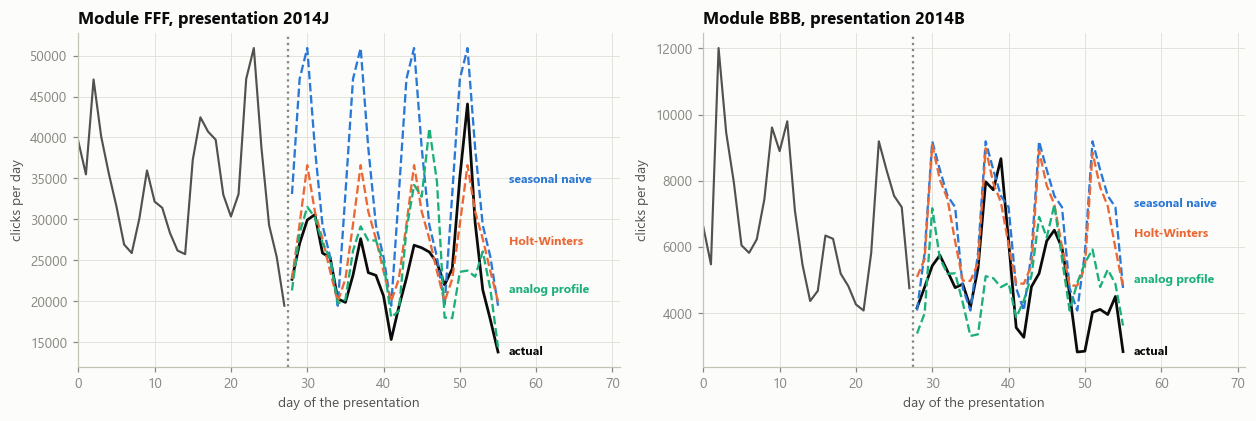

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
for ax, k in zip(axes, [("FFF", "2014J"), ("BBB", "2014B")]):
    y = SER[k].loc[0:55].values; tr, act = y[:28], y[28:]; fcs = fc_methods(tr)
    yt = SER[twin[k]].loc[0:55].values; fcs["analog profile (last year's twin)"] = yt[28:] * (tr[14:28].sum() / yt[14:28].sum())
    ax.plot(range(28), tr, color=INK2, linewidth=1.4); ax.plot(range(28, 56), act, color=INK, linewidth=1.8)
    ends = [("actual", act[-1], INK)]
    for nm, col in [("seasonal naive", C1), ("Holt-Winters (damped, weekly)", C2), ("analog profile (last year's twin)", C3)]:
        ax.plot(range(28, 56), fcs[nm], color=col, linewidth=1.5, linestyle="--"); ends.append((nm.split(" (")[0], np.mean(fcs[nm][-7:]), col))
    gap = 0.075 * max(act.max(), tr.max()); ys = []
    for lab, v, col in sorted(ends, key=lambda e: e[1]):                      # spread the end labels so that they do not overlap
        ys.append(v if not ys else max(v, ys[-1] + gap)); ax.text(56.4, ys[-1], lab, color=col, fontsize=8, va="center", fontweight="bold")
    ax.axvline(27.5, color=MUTED, linestyle=":"); ax.set_xlim(0, 71); ax.set_xlabel("day of the presentation"); ax.set_title(f"Module {k[0]}, presentation {k[1]}")
axes[0].set_ylabel("clicks per day"); axes[1].set_ylabel("clicks per day"); fig.tight_layout(); savefig(fig, "07c_forecast_examples.png"); plt.show()

In [8]:
# Does the error grow with the horizon? sMAPE by week of the holdout, same series as above
rows = []
for k in keys:
    y = SER[k].loc[0:TRAIN + H - 1].values; tr, act = y[:TRAIN], y[TRAIN:]; fcs = fc_methods(tr)
    if k in twin:
        yt = SER[twin[k]].loc[0:TRAIN + H - 1].values; fcs["analog profile (last year's twin)"] = yt[TRAIN:] * (tr[14:28].sum() / max(yt[14:28].sum(), 1.0))
    for nm, f in fcs.items():
        for w in range(4):
            a_, f_ = act[w * 7:(w + 1) * 7], f[w * 7:(w + 1) * 7]; rows.append(dict(method=nm, week=w + 5, smape=np.mean(2 * np.abs(a_ - f_) / (np.abs(a_) + np.abs(f_) + 1e-9)), has_twin=k in twin))
hz = pd.DataFrame(rows)
display(hz[hz.method != "analog profile (last year's twin)"].pivot_table(index="method", columns="week", values="smape", aggfunc="median"))
display(hz[hz.has_twin].pivot_table(index="method", columns="week", values="smape", aggfunc="median"))

week,5,6,7,8
method,,,,
"Holt-Winters (damped, weekly)",0.179,0.251,0.298,0.299
flat mean (last week),0.280,0.345,0.307,0.327
naive,0.259,0.236,0.241,0.279
seasonal naive,0.249,0.326,0.288,0.296


week,5,6,7,8
method,,,,
"Holt-Winters (damped, weekly)",0.170,0.226,0.279,0.361
analog profile (last year's twin),0.129,0.192,0.141,0.224
flat mean (last week),0.294,0.345,0.289,0.396
naive,0.254,0.252,0.216,0.357
seasonal naive,0.262,0.325,0.284,0.290


**Observed (22 series, forecasting days 28 to 55).** All four standard methods beat the in-sample seasonal-naive error (median MASE 0.57 to 0.61) and are close to each other: seasonal naive has the lowest median MASE (0.57) but a long tail (mean 0.88); the plain naive forecast has the lowest mean MASE (0.61) and the lowest median sMAPE (27%). Holt-Winters is not better (median MASE 0.60, mean 0.69) and over-forecasts by 20% at the median, while the naive forecast under-forecasts by 14%.
**Observed (the 9 series with a 2013 twin, all methods on the same series).** The **analog profile** is clearly the most accurate in relative terms: sMAPE 17% against 29% (Holt-Winters), 30% (seasonal naive) and 27% (naive), almost no bias (-4%, against +12% for Holt-Winters and +29% for seasonal naive), and the lowest mean MASE (0.54 against 0.73, 1.05 and 0.69). Its median MASE (0.64) is about the same as Holt-Winters (0.62). By week of the holdout its sMAPE is 13%, 19%, 14% and 22%, while Holt-Winters worsens from 17% to 36% and the naive forecasts from 25% to 36%.
**Why it matters.** With only 28 days to learn from, a statistical model cannot know the rhythm of the course; last year's twin carries the deadline calendar and the decay shape, and it stays accurate over the whole four-week horizon. The price is data: a twin exists for only 9 of the 13 presentations of 2014.
**Action.** Use the analog profile where a twin exists and the seasonal naive forecast otherwise; revisit when more years are available (a calendar-aware regression is the next candidate).
**Caveats.** One holdout window per series, 22 series and 9 twins, no prediction intervals; the conclusions are about relative accuracy, not about precise capacity planning.

# Part B. Designing an A/B test of proactive outreach

**Decision to be supported.** Should tutors contact students flagged by the early-warning model? The model says who is at risk, not whether contact helps.

## B1. The population and its baseline rate

The 2014 students in the top 30% of predicted risk (the flagging policy of notebook 07a) form the population an outreach programme would see in a year.

In [9]:
pred = pd.read_csv(PROC / "oulad_predictions_2014.csv")
thr = np.quantile(pred.p_nosens, 0.70)            # alert model without the socio-economic features (recommendation of 07a)
flag = pred[pred.p_nosens >= thr].reset_index(drop=True)
N_flag = len(flag); base = flag.target_at_risk.mean()
print(f"flagged students (top 30%): {N_flag:,} | observed at-risk rate among them: {base:.3f} | mean predicted risk: {flag.p_nosens.mean():.3f}")
print("per module-presentation (flagged students):"); display(flag.groupby(["code_module", "code_presentation"]).size().describe()[["min", "50%", "max"]].to_frame("flagged students"))

flagged students (top 30%): 4,721 | observed at-risk rate among them: 0.751 | mean predicted risk: 0.737
per module-presentation (flagged students):


,flagged students
min,49.000
50%,397.000
max,973.000


**Observed.** The top 30% of predicted risk in 2014 contains 4,721 students, of whom 75.1% ended up at risk (the model predicted 73.7% on average). The median module-presentation has only 397 flagged students (range 49 to 973).

## B2. Sample size and minimum detectable effect

Primary outcome: **ending the presentation at risk** (Fail or Withdrawn), analysed as the difference in proportions between outreach and usual support, two-sided test at the 5% level.

In [10]:
pw = NormalIndPower()
rows = []
for delta in (0.02, 0.03, 0.04, 0.05, 0.07, 0.10):
    for power in (0.80, 0.90):
        h = proportion_effectsize(base, base - delta); n = pw.solve_power(effect_size=h, alpha=0.05, power=power, ratio=1.0)
        rows.append(dict(true_reduction_points=delta * 100, power=power, n_per_arm=int(np.ceil(n)), total=int(2 * np.ceil(n)), share_of_flagged_students=2 * np.ceil(n) / N_flag))
ss = pd.DataFrame(rows); display(ss.pivot(index="true_reduction_points", columns="power", values="n_per_arm"))
GROUP_N = {"all flagged students in one year": N_flag, "a median module (both presentations)": int(flag.groupby("code_module").size().median()),
           "a median module-presentation": int(flag.groupby(MPK).size().median())}
MDE = {}
for label, n_total in GROUP_N.items():
    n_arm = n_total // 2
    MDE[label] = next(d for d in np.arange(0.005, 0.40, 0.0025) if pw.power(proportion_effectsize(base, base - d), nobs1=n_arm, alpha=0.05, ratio=1.0) >= 0.80)
    print(f"{label}: {n_total:,} flagged students, {n_arm:,} per arm -> minimum detectable reduction {MDE[label] * 100:.1f} points at 80% power")
ss.to_csv(OUT / "ab_sample_size.csv", index=False)

power,0.800,0.900
true_reduction_points,,
2.000,7524,10072
3.000,3384,4531
4.000,1926,2578
5.000,1246,1668
7.000,649,869
10.000,327,438


all flagged students in one year: 4,721 flagged students, 2,360 per arm -> minimum detectable reduction 3.7 points at 80% power
a median module (both presentations): 612 flagged students, 306 per arm -> minimum detectable reduction 10.5 points at 80% power
a median module-presentation: 397 flagged students, 198 per arm -> minimum detectable reduction 13.2 points at 80% power


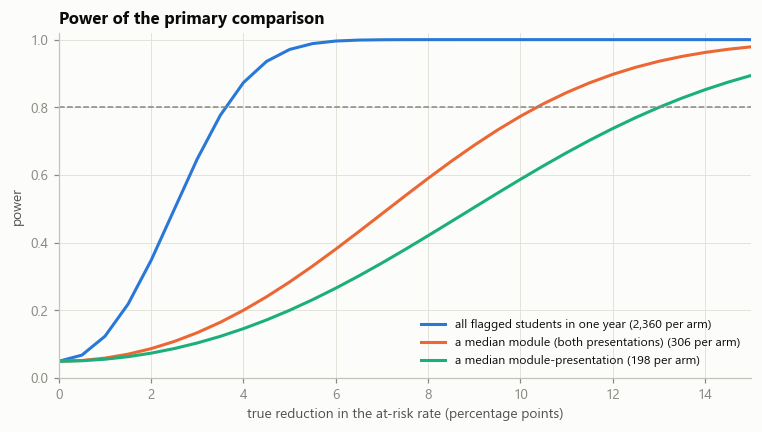

In [11]:
n_arm = N_flag // 2
fig, ax = plt.subplots(figsize=(7, 4))
deltas = np.arange(0, 0.151, 0.005)
for (lab, n_tot), col in zip(GROUP_N.items(), (C1, C2, C3)):
    n_a = n_tot // 2
    ax.plot(deltas * 100, [pw.power(proportion_effectsize(base, base - d), nobs1=n_a, alpha=0.05) if d > 0 else 0.05 for d in deltas], color=col, linewidth=2, label=f"{lab} ({n_a:,} per arm)")
ax.axhline(0.8, color=MUTED, linestyle="--", linewidth=1); ax.set_xlim(0, 15); ax.set_ylim(0, 1.02); ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_xlabel("true reduction in the at-risk rate (percentage points)"); ax.set_ylabel("power")
ax.set_title("Power of the primary comparison"); fig.tight_layout(); savefig(fig, "07c_power_curves.png"); plt.show()

**Observed.** To detect a reduction in the at-risk rate at 80% power one needs 7,524 students per arm for 2 points, 3,384 for 3 points, 1,246 for 5 points and 327 for 10 points (90% power: 10,072, 4,531, 1,668 and 438). One year of flagged students gives 2,360 per arm, enough to detect a **3.7-point** reduction. A median module alone (306 per arm) could only detect **10.5 points** and a single module-presentation (198 per arm) **13.2 points**.
**Why it matters.** Outreach is unlikely to cut the at-risk rate of a high-risk group by 10 points or more, so a trial limited to one module or one presentation would almost certainly be inconclusive. The trial has to pool all modules and, realistically, run for two or three presentations.

## B3. Simulation: type I error, power and the value of adjusting for the risk score

Each flagged student gets the outcome probability predicted by the model (it is well calibrated, see 07a); outreach lowers it by an absolute amount tau. Students are randomised 1:1 and the trial is simulated 600 times for each scenario. Three analyses are compared: the plain difference in proportions, a logistic regression that adjusts for the risk score, and a stratified analysis (Mantel-Haenszel) by module.

In [12]:
from statsmodels.stats.contingency_tables import StratifiedTable
rng = np.random.RandomState(RANDOM_STATE)
p0 = flag.p_nosens.values.copy(); logit_p = np.log(p0 / (1 - p0)); mod_codes = pd.factorize(flag.code_module)[0]
def simulate(tau, nsim=600, n=None):
    n = N_flag if n is None else n; rej = {"plain": 0, "adjusted": 0, "stratified": 0}; est = []
    for _ in range(nsim):
        idx = rng.choice(N_flag, n, replace=False) if n < N_flag else np.arange(N_flag)
        T = rng.permutation(np.repeat([0, 1], [n - n // 2, n // 2])); pi = np.clip(p0[idx] - tau * T, 0.001, 0.999); y = rng.binomial(1, pi)
        a, b = y[T == 1].sum(), (T == 1).sum() - y[T == 1].sum(); c, d_ = y[T == 0].sum(), (T == 0).sum() - y[T == 0].sum()
        z = (a / (a + b) - c / (c + d_)) / np.sqrt(((a + c) / n) * (1 - (a + c) / n) * (1 / (a + b) + 1 / (c + d_))); est.append(a / (a + b) - c / (c + d_))
        rej["plain"] += abs(z) > 1.96
        X = sm.add_constant(np.column_stack([T, logit_p[idx]])); fit = sm.Logit(y, X).fit(disp=0, maxiter=30); rej["adjusted"] += fit.pvalues[1] < 0.05
        tabs = [np.array([[((T == 1) & (y == 1) & (mod_codes[idx] == m)).sum(), ((T == 1) & (y == 0) & (mod_codes[idx] == m)).sum()], [((T == 0) & (y == 1) & (mod_codes[idx] == m)).sum(), ((T == 0) & (y == 0) & (mod_codes[idx] == m)).sum()]]) + 0.5 for m in np.unique(mod_codes[idx])]
        rej["stratified"] += StratifiedTable(tabs).test_null_odds().pvalue < 0.05
    return {k: v / nsim for k, v in rej.items()}, np.mean(est), np.std(est)
rows = []
for tau, n in [(0.0, None), (0.03, None), (0.05, None), (0.05, 800), (0.05, 400), (0.10, 400)]:
    r, m_, s_ = simulate(tau, n=n)
    rows.append(dict(true_reduction=tau, students_in_trial=n or N_flag, rejection_plain=r["plain"], rejection_adjusted=r["adjusted"], rejection_stratified=r["stratified"], mean_estimate=-m_, sd_of_estimate=s_))
sim = pd.DataFrame(rows); sim.to_csv(OUT / "ab_power_simulation.csv", index=False); sim

,true_reduction,students_in_trial,rejection_plain,rejection_adjusted,rejection_stratified,mean_estimate,sd_of_estimate
0,0.000,4721,0.060,0.060,0.058,0.000,0.013
1,0.030,4721,0.693,0.705,0.692,0.032,0.013
2,0.050,4721,0.967,0.983,0.973,0.050,0.013
3,0.050,800,0.387,0.390,0.367,0.052,0.033
4,0.050,400,0.208,0.233,0.203,0.052,0.047
5,0.100,400,0.535,0.555,0.525,0.095,0.046


**Observed (600 simulated trials per scenario, outcomes drawn from the model's own probabilities).** The test keeps its size: with no effect the plain, adjusted and stratified analyses reject 6.0%, 6.0% and 5.8% of the time (nominal 5%; the simulation error is about 0.9 points). Power matches the table: a true 3-point reduction is detected 69% to 71% of the time with all 4,721 students, and a 5-point reduction 97% to 98%. With only 800 students the power for 5 points is 39%, with 400 students 21% to 23% (and 53% to 56% even for a 10-point effect). The estimate is precise with the full sample (standard deviation 1.3 points) and noisy with 400 (4.7 points).
**Adjusting for the risk score** adds at most 2.5 points of power and stratifying by module nothing, because the predicted risk varies little among the flagged students (they are all high risk). Sample size, not the analysis method, determines whether the trial can answer the question.

## B4. Why not just compare contacted and not contacted students?

If tutors contact the students the model flags (no randomisation), the contacted group is, by construction, the high-risk group. The naive comparison then says contact is *harmful*. A regression-discontinuity analysis around the flag threshold is the best observational alternative.

In [13]:
rng = np.random.RandomState(7); tau_true = 0.05
allp = pred.p_nosens.values; N_all = len(allp)
def one_world():
    T = (allp >= thr).astype(int); y = rng.binomial(1, np.clip(allp - tau_true * T, 0.001, 0.999))
    naive = y[T == 1].mean() - y[T == 0].mean()
    out = {}
    for bw in (0.03, 0.06):
        near = np.abs(allp - thr) <= bw; above, below = near & (T == 1), near & (T == 0)
        # local linear fit of the outcome on the risk score on each side, evaluated at the threshold
        def at_thr(m):
            X = np.column_stack([np.ones(m.sum()), allp[m] - thr]); b = np.linalg.lstsq(X, y[m], rcond=None)[0]; return b[0]
        out[f"RD bw {bw}"] = at_thr(above) - at_thr(below); out[f"n_bw{bw}"] = int(near.sum())
    return naive, out
res_ = [one_world() for _ in range(300)]
naive_vals = np.array([r[0] for r in res_])
rd = pd.DataFrame([r[1] for r in res_])
cmp_ = pd.DataFrame({"true effect of contact": [-tau_true] * 3,
                     "estimate (mean of 300 simulated worlds)": [naive_vals.mean(), rd["RD bw 0.03"].mean(), rd["RD bw 0.06"].mean()],
                     "sd of estimate": [naive_vals.std(), rd["RD bw 0.03"].std(), rd["RD bw 0.06"].std()],
                     "students used": [N_all, int(rd["n_bw0.03"].mean()), int(rd["n_bw0.06"].mean())]},
                    index=["naive: contacted (flagged) vs not contacted", "regression discontinuity, bandwidth 0.03", "regression discontinuity, bandwidth 0.06"])
cmp_.to_csv(OUT / "ab_observational_vs_rd.csv"); cmp_

,true effect of contact,estimate (mean of 300 simulated worlds),sd of estimate,students used
naive: contacted (flagged) vs not contacted,-0.050,0.362,0.008,15735
"regression discontinuity, bandwidth 0.03",-0.050,-0.046,0.063,979
"regression discontinuity, bandwidth 0.06",-0.050,-0.047,0.048,1953


**Observed.** The naive comparison of contacted (flagged) and not contacted students estimates a difference of **+36 points** in the at-risk rate: contacted students look 36 points *worse*, although in the simulation contact truly *lowers* the rate by 5 points. Contact went to the students who were already most at risk (confounding by indication), so the comparison measures the model, not the outreach.
A regression discontinuity around the flagging threshold gets the sign and size right on average (-4.6 and -4.7 points against a true -5), because students just above and just below the threshold are alike. But it uses only 979 to 1,953 students and is noisy: its standard deviation is 4.8 to 6.3 points, against 1.3 for the randomised trial, so a single analysis could not tell a 5-point effect from none.
**Why it matters.** Only randomisation answers "does outreach help?" convincingly. Regression discontinuity is a credible fallback when randomising is not allowed, but only if the cut-off is applied strictly, and it needs several presentations to be precise. (In this simulation the assumptions of the method hold by construction, which flatters it.)

## B5. Experiment plan

In [14]:
plan = pd.DataFrame([
    ("Question", "Does proactive tutor outreach to flagged students reduce the share who end the presentation at risk?"),
    ("Population", "Students in the top 30% of predicted risk at day 28 (alert model without socio-economic features), all modules"),
    ("Unit of randomisation", "Student; stratified by module-presentation and by risk tercile. Randomise by tutor group instead if tutors would treat both arms (contamination)"),
    ("Arms", "A: usual support (no extra contact). B: structured outreach within one week of the alert. 1:1 allocation"),
    ("Primary outcome", "Ends the presentation at risk (Fail or Withdrawn). Analysis: difference in proportions with a confidence interval; adjusted analysis as a pre-specified secondary"),
    ("Secondary outcomes", "Submission of the next assessment (known by day 56), final score of passers, withdrawal alone. Multiple secondaries are corrected (Benjamini-Hochberg)"),
    ("Guardrails", "Complaints or opt-outs, workload per tutor, outcomes of the unflagged students (spillover), outcome gaps between deprivation groups"),
    ("Sample size", f"{N_flag:,} flagged students per year give {N_flag // 2:,} per arm: detects a {MDE['all flagged students in one year'] * 100:.1f} point reduction at 80% power. A median module alone could only detect {MDE['a median module (both presentations)'] * 100:.0f} points and a module-presentation {MDE['a median module-presentation'] * 100:.0f} points, so pool the modules, run several presentations, and treat modules as exploratory"),
    ("Duration and timing", "Outcome known at the end of the presentation (about 8 months); interim look at day 56 on the next-assessment outcome only; no early stopping on the primary outcome without a pre-set alpha-spending rule"),
    ("Analysis plan", "Intention to treat. Pre-registered subgroups: deprivation band and module (exploratory, with interaction tests). No peeking-based decisions"),
    ("Ethics", "Control students keep the usual support and receive outreach after the trial if it works (delayed rollout). Contact is supportive, not a label; data minimised; students informed"),
    ("Threats", "Contamination between arms, tutor differences, novelty effect, model drift during the trial (monitor inputs, see 07b), and alerts that change student behaviour before outreach"),
], columns=["element", "decision"]).set_index("element")
plan.to_csv(OUT / "ab_experiment_plan.csv"); plan

,decision
element,
Question,Does proactive tutor outreach to flagged stude...
Population,Students in the top 30% of predicted risk at d...
Unit of randomisation,Student; stratified by module-presentation and...
Arms,A: usual support (no extra contact). B: struct...
Primary outcome,Ends the presentation at risk (Fail or Withdra...
Secondary outcomes,Submission of the next assessment (known by da...
Guardrails,"Complaints or opt-outs, workload per tutor, ou..."
Sample size,"4,721 flagged students per year give 2,360 per..."
Duration and timing,Outcome known at the end of the presentation (...


## Synthesis

**Part A (time series).** Platform activity is dominated by a decaying trend and a strong deadline calendar (1.9 to 3.2 times the local level the day before a due date), with only a modest weekly cycle. For the four weeks after the alert date, simple methods are hard to beat: seasonal naive and naive forecasts have similar errors and Holt-Winters adds nothing, with a bias of +20%. The method that uses last year's twin of the same module halves the relative error (sMAPE 17% against about 29%), removes the bias and stays accurate over the whole horizon, so it is the recommended forecast where a twin exists.

**Part B (A/B test).** The model can only say who is at risk. Whether contact helps needs a randomised trial: with 4,721 flagged students a year the pooled trial detects a 3.7-point reduction (80% power), a single module only about 10 points, and a single presentation 13 points. Comparing contacted with not-contacted students without randomisation would wrongly suggest that contact is harmful (+36 points in the simulation). A regression discontinuity is a fallback but about four times noisier.

**Limits.** The forecast evidence rests on 22 series and 9 twins. The trial design assumes that the model's predicted probabilities stay calibrated (07b monitoring) and that outreach does not change the behaviour of students in the control arm.

**Recommendation.** Run the pooled randomised trial for two or three presentations with the pre-specified plan above, report modules as exploratory, and use the twin-based forecast for staffing in the meantime.